<a href="https://colab.research.google.com/github/sohyun223/ai-application-2026/blob/main/Week13_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13주차 실습 — 경량화와 안전 장치: 지연 · INT8 양자화 · OOD 감지 · 안전 래퍼 · 배포 점검
**AI Application · 스마트모빌리티학과 · 2026-11-25**

| 셀 | 내용 |
|---|---|
| 0-1 | 이 머신의 속도 측정 → 예상 실행 시간, FAST |
| 1 | 지연 측정 — p50 / p99, 스레드 1·2·4 |
| 2 | INT8 정적 양자화 — 기본 캘리브레이션 vs 랜덤화(저조도·노이즈) 캘리브레이션: 크기·지연·MAE·L1·L3 |
| 3 | OOD 감지 — 특징 거리(마할라노비스) + 정책 불일치: 점수 분포, AUROC, 임계값 τ |
| 4 | 안전 래퍼 — OOD 폴백(자동 노출 보정 모듈형) + 변화율 제한: L1 / 저조도·노이즈 / L3 전후, 개입 비율, 저크 |
| 5 | 배포 점검(ONNX 계약·지연) 자동 검사 + L1~L5 자가 평가 → self_eval.json |

**준비물**: `tinytrack.py` (0.3.1), Drive 의 `week11/pilot_dr.pt` 또는 `week07/my_policy_v2.pt`(없으면 즉석). CPU 로 전체 6~8분.

In [1]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json, copy, shutil
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch, torch.nn as nn, onnxruntime as ort
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
assert tt.__version__ >= "0.3.1", "tinytrack 0.3.1 이상 필요"
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week13"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
H, W = tt.H, tt.W
MODELS = Path("models") if Path("models/base_pilotnet.pt").exists() else Path(".")

for cand in [ROOT / "week07" / "my_dataset_v2.npz", ROOT / "week05" / "my_dataset_v1.npz"]:
    if cand.exists():
        D = tt.load_npz(cand); print("데이터:", cand.name, len(D["steers"])); break
else:
    print("데이터가 없어 즉석 생성 (약 20초)")
    D = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
D = {k: D[k] for k in ("images", "steers", "states", "run_id")}; tr, va = tt.split_by_run(D, 0.2, seed=0)
for cand in [ROOT / "week07" / "my_policy_v2.pt", ROOT / "week06" / "my_policy_v1.pt"]:
    if cand.exists():
        model = tt.load_model(cand); print("torch 정책:", cand.name); break
else:
    if not (MODELS / "base_pilotnet.pt").exists():
        from google.colab import files
        print("base_pilotnet.pt 업로드"); files.upload()
    model = tt.load_model(MODELS / "base_pilotnet.pt"); tt.train_bc(model, tr, va, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), verbose=False); print("torch 정책: 즉석 미세조정")
FP32 = tt.export_onnx(model.cpu().eval(), SAVE_DIR / "policy_fp32.onnx")
PUBLIC = ["A", "B", "C"]
L1 = tt.level_eval_kwargs("L1"); L3 = tt.level_eval_kwargs("L3", style_seed=7)
DARK = dict(disturb=tt.DEFAULT_DISTURB, style=dict(brightness=tt.CHALLENGE_LEVELS["L3"]["brightness"]), noise=tt.CHALLENGE_LEVELS["L3"]["noise"])   # L3 에서 색 랜덤화만 뺀 것
def score(pol, kw): return round(tt.evaluate(pol, PUBLIC, seed=0, **kw)["score"], 1)
def mae(pol, ds, n=300): return round(tt.offline_mae(pol, ds, n=n)[0], 4)
print("tinytrack", tt.__version__, "| FP32:", FP32)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
데이터: my_dataset_v2.npz 4150
torch 정책: my_policy_v2.pt
tinytrack 0.3.1 | FP32: /content/drive/MyDrive/AIApp/week13/policy_fp32.onnx


### 0-1. 이 머신의 속도 측정 (5초) → 예상 실행 시간과 `FAST`

In [2]:
import time as _t
_t0 = _t.time(); [tt.render(0.1, 0.05, 0.1) for _ in range(300)]; _tr = _t.time() - _t0
_m = tt.make_model().eval(); _x = torch.zeros(64, 3, tt.H, tt.W)
with torch.no_grad():
    _m(_x); _t0 = _t.time(); [_m(_x) for _ in range(10)]; _tf = _t.time() - _t0
REF_RENDER, REF_FWD, REF_MIN = 0.195, 0.318, 7
ratio = 0.5 * (_tr / REF_RENDER) + 0.5 * (_tf / REF_FWD)
FAST = os.environ.get("NB_FAST") == "1" or ratio > 1.8
print(f"렌더 300장 {_tr:.2f}s · 순전파 10회 {_tf:.2f}s → 제작 PC 대비 {ratio:.1f}배 → 예상 전체 실행 약 {REF_MIN * ratio * (0.7 if FAST else 1.0):.0f}분 | FAST = {FAST}")

렌더 300장 0.28s · 순전파 10회 1.44s → 제작 PC 대비 3.0배 → 예상 전체 실행 약 15분 | FAST = True


## 1. 지연 측정 — 평균이 아니라 p99
배치 1, 워밍업 10회 후 300회. 스레드 1·2·4 로 p50/p99/최대를 비교합니다. 노트북에서 다른 작업이 돌면 p99 가 튀는 것을 볼 수 있습니다.

In [3]:
def latency(onnx_path, images, threads=2, n=300):
    pol = tt.OnnxPolicy(onnx_path, threads=threads)
    for im in images[:10]: pol(im)
    ts = []
    for im in images[:n]:
        t0 = time.perf_counter(); pol(im); ts.append((time.perf_counter() - t0) * 1000)
    ts = np.array(ts); return dict(p50=round(np.percentile(ts, 50), 3), p99=round(np.percentile(ts, 99), 3), max=round(ts.max(), 2))
rows = [dict(threads=th, **latency(FP32, D["images"], th)) for th in (1, 2, 4)]
print(pd.DataFrame(rows).to_string(index=False))
print("읽는 법: 33 ms 예산은 p99 로 판단. 스레드를 늘려도 배치 1 에선 이득이 작고 p99 가 오히려 튈 수 있다 — 배포는 threads=2 고정")

 threads   p50    p99   max
       1 1.577  4.377  4.85
       2 1.025  5.292  6.18
       4 5.444 12.298 15.26
읽는 법: 33 ms 예산은 p99 로 판단. 스레드를 늘려도 배치 1 에선 이득이 작고 p99 가 오히려 튈 수 있다 — 배포는 threads=2 고정


## 2. INT8 정적 양자화 — 캘리브레이션도 분포 문제
같은 FP32 ONNX 를 두 가지 캘리브레이션 세트로 양자화합니다: **기본**(학습 프레임 200장) vs **랜덤화**(저조도·노이즈·색 프레임 포함 200장). 크기·지연·오프라인 MAE·L1·L3 를 한 표에.

In [4]:
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat
from onnxruntime.quantization.shape_inference import quant_pre_process
class Reader(CalibrationDataReader):
    def __init__(self, images): self.it = iter([{"image": tt.preprocess(im)} for im in images])
    def get_next(self): return next(self.it, None)

rng = np.random.RandomState(0)
calib_basic = D["images"][rng.choice(len(D["images"]), 200, replace=False)]
calib_rand = np.stack([tt.render(*D["states"][k][:3], noise=float(rng.uniform(0.0, 0.3)), style=dict(tt.random_style(int(rng.randint(1000)), 1.0), brightness=float(rng.uniform(0.3, 1.2))), rng=rng)
                       for k in rng.choice(len(D["images"]), 200, replace=False)])
pre = SAVE_DIR / "policy_fp32_pre.onnx"; quant_pre_process(str(FP32), str(pre))          # shape 추론·상수 접기 (양자화 전처리)
paths = {"FP32": FP32}
for name, calib in [("INT8 기본 캘리브레이션", calib_basic), ("INT8 랜덤화 캘리브레이션", calib_rand)]:
    out = SAVE_DIR / f"policy_{'int8_basic' if '기본' in name else 'int8_rand'}.onnx"
    quantize_static(str(pre), str(out), Reader(calib), quant_format=QuantFormat.QDQ, per_channel=True, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
    paths[name] = out
rows = []; t0 = time.time()
for name, p in paths.items():
    pol = tt.OnnxPolicy(p); lat = latency(p, D["images"], 2, 200)
    rows.append(dict(model=name, kb=os.path.getsize(p) // 1024, p50=lat["p50"], p99=lat["p99"], mae=mae(pol, va), L1=score(pol, L1), dark=score(pol, DARK), L3=score(pol, L3)))
    print(rows[-1], flush=True)
qdf = pd.DataFrame(rows); qdf.to_csv(SAVE_DIR / "quantization.csv", index=False); print(f"({time.time()-t0:.0f}s)")
print("읽는 법: 크기 1/3~1/4, 지연은 CPU·모델 크기에 따라 이득이 작을 수 있음. L1 은 그대로인데 dark/L3 가 떨어지면 캘리브레이션이 그 분포를 안 덮은 것")

{'model': 'FP32', 'kb': 988, 'p50': np.float64(1.025), 'p99': np.float64(6.015), 'mae': 0.0312, 'L1': 86.7, 'dark': 23.1, 'L3': 25.4}
{'model': 'INT8 기본 캘리브레이션', 'kb': 267, 'p50': np.float64(1.021), 'p99': np.float64(2.048), 'mae': 0.0404, 'L1': 86.8, 'dark': 23.1, 'L3': 25.4}
{'model': 'INT8 랜덤화 캘리브레이션', 'kb': 267, 'p50': np.float64(0.962), 'p99': np.float64(1.234), 'mae': 0.0349, 'L1': 87.0, 'dark': 23.1, 'L3': 25.5}
(131s)
읽는 법: 크기 1/3~1/4, 지연은 CPU·모델 크기에 따라 이득이 작을 수 있음. L1 은 그대로인데 dark/L3 가 떨어지면 캘리브레이션이 그 분포를 안 덮은 것


## 3. OOD 감지 — 모를 때를 아는 법
① **특징 거리**: 정책 트렁크의 마지막 특징(1152차원)을 PCA 32차원으로 줄이고 학습 데이터의 평균·공분산으로 마할라노비스 거리. ② **정책 불일치**: E2E 조향 vs 모듈형(도로 마스크→PD, 자동 노출 보정) 조향의 차이.
정상(검증 프레임) vs 분포 밖(저조도·노이즈·색 랜덤화) 점수 분포와 AUROC, 임계값 τ = 정상의 99 분위수.

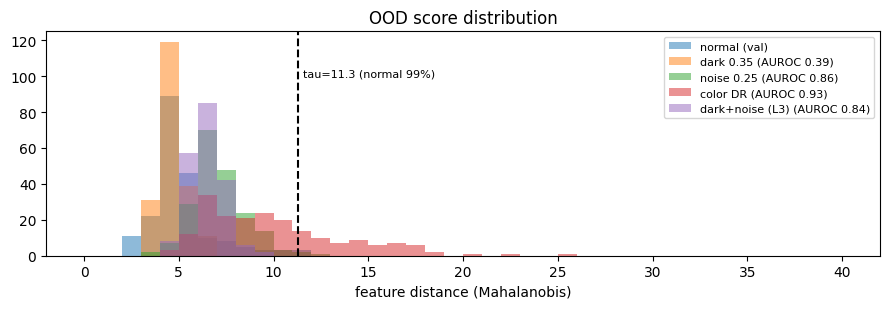

τ = 11.3 (정상 점수의 99 분위수)
  정상(검증)        : 중앙값   4.8 | τ 초과율 0.01
  저조도           : 중앙값   4.4 | τ 초과율 0.00 | AUROC 0.39
  노이즈 0.25      : 중앙값   6.9 | τ 초과율 0.01 | AUROC 0.86
  색 랜덤화         : 중앙값   9.5 | τ 초과율 0.30 | AUROC 0.93
  저조도+노이즈 (L3)  : 중앙값   6.4 | τ 초과율 0.00 | AUROC 0.84
읽는 법: 분포 밖에서 점수가 커지고 τ 초과율이 높으면 감지기가 작동. 중앙값은 커졌는데 τ 초과율이 0 이면 '순위로는 구별되지만 99 분위 임계값이 너무 높다' — AUROC 와 τ 초과율을 함께 볼 것. 색 랜덤화처럼 정책이 '버티는' 조건에서도 경보가 나면 헛경보 — 감지기와 정책의 취약점이 같지 않다


In [5]:
feat_net = model.features.eval()
def feats(images):
    out = []
    with torch.no_grad():
        for s in range(0, len(images), 128):
            x = torch.from_numpy(np.concatenate([tt.preprocess(im) for im in images[s:s + 128]])); out.append(feat_net(x).flatten(1).numpy())
    return np.concatenate(out)
Ftr = feats(tr["images"][:1500]); mu0 = Ftr.mean(0)
U, S, Vt = np.linalg.svd(Ftr - mu0, full_matrices=False); P = Vt[:32].T                   # PCA 32 (numpy SVD)
Z = (Ftr - mu0) @ P; mu, cov = Z.mean(0), np.cov(Z.T) + 1e-3 * np.eye(32); inv = np.linalg.inv(cov)
def ood_score(images):
    Zq = (feats(images) - mu0) @ P - mu; return np.sqrt(np.einsum("ij,jk,ik->i", Zq, inv, Zq))
rng = np.random.RandomState(1); k = rng.choice(len(va["images"]), 200, replace=False); st = va["states"][k]
sets = {"정상(검증)": va["images"][k],
        "저조도": np.stack([tt.render(*s[:3], style=dict(brightness=0.35), rng=rng) for s in st]),
        "노이즈 0.25": np.stack([tt.render(*s[:3], noise=0.25, rng=rng) for s in st]),
        "색 랜덤화": np.stack([tt.render(*s[:3], style=tt.random_style(int(rng.randint(1000)), 1.0), rng=rng) for s in st]),
        "저조도+노이즈 (L3)": np.stack([tt.render(*s[:3], noise=0.25, style=dict(brightness=0.35), rng=rng) for s in st])}
scores = {n: ood_score(im) for n, im in sets.items()}; tau = float(np.percentile(scores["정상(검증)"], 99))
def auroc(pos, neg):                                                     # 순위 기반 (sklearn 없이)
    allv = np.concatenate([pos, neg]); ranks = allv.argsort().argsort() + 1
    return float((ranks[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))
EN = {"정상(검증)": "normal (val)", "저조도": "dark 0.35", "노이즈 0.25": "noise 0.25", "색 랜덤화": "color DR", "저조도+노이즈 (L3)": "dark+noise (L3)"}   # Colab 에 한글 글꼴이 없어 그림은 영어
plt.figure(figsize=(9, 3.2))
for n, s in scores.items(): plt.hist(np.clip(s, 0, 40), bins=40, range=(0, 40), alpha=.5, label=f"{EN[n]} (AUROC {auroc(s, scores['정상(검증)']):.2f})" if n != "정상(검증)" else EN[n])
plt.axvline(tau, c="k", ls="--"); plt.text(tau + 0.3, plt.ylim()[1] * 0.8, f"tau={tau:.1f} (normal 99%)", fontsize=8); plt.legend(fontsize=8); plt.xlabel("feature distance (Mahalanobis)"); plt.title("OOD score distribution")
plt.tight_layout(); plt.savefig(SAVE_DIR / "ood_scores.png", dpi=120); plt.show()
print(f"τ = {tau:.1f} (정상 점수의 99 분위수)")
for n, s in scores.items(): print(f"  {n:14s}: 중앙값 {np.median(s):5.1f} | τ 초과율 {np.mean(s > tau):.2f}" + ("" if n == "정상(검증)" else f" | AUROC {auroc(s, scores['정상(검증)']):.2f}"))
print("읽는 법: 분포 밖에서 점수가 커지고 τ 초과율이 높으면 감지기가 작동. 중앙값은 커졌는데 τ 초과율이 0 이면 '순위로는 구별되지만 99 분위 임계값이 너무 높다' — AUROC 와 τ 초과율을 함께 볼 것. 색 랜덤화처럼 정책이 '버티는' 조건에서도 경보가 나면 헛경보 — 감지기와 정책의 취약점이 같지 않다")

## 4. 안전 래퍼 — 감시자 → 폴백 → 변화율 제한
폴백은 8주차 모듈형(도로 마스크→PD)에 **자동 노출 보정**(이미지를 평균 밝기로 정규화)과 3×3 블러를 넣은 것 — 규칙은 이렇게 한 줄로 고칠 수 있습니다. 감시자 = 특징 거리 > τ **또는** E2E·모듈형 조향 차이 > 0.5 가 k=3 프레임 연속. 모든 출력은 스텝당 변화 0.15 이하.

In [6]:
ROAD = np.array(tt.DEFAULT_STYLE["road"], np.float32); ROWS = np.arange(tt.Y_HORIZON + 4, H)
def blur3(f):
    p = np.pad(f, ((1, 1), (1, 1), (0, 0)), mode="edge"); return sum(p[i:i + H, j:j + W] for i in range(3) for j in range(3)) / 9.0
def road_mask(img, tol=0.12):
    f = blur3(img.astype(np.float32) / 255); f = f * (0.45 / max(f[ROWS].mean(), 1e-3))    # 자동 노출 보정: 노면 영역 평균 밝기를 기준값으로
    return np.abs(f - ROAD).max(axis=2) < tol
_m0 = road_mask(tt.render(0, 0, 0)); ROAD_W_PX = {r: (np.where(_m0[r])[0].max() - np.where(_m0[r])[0].min()) for r in ROWS if _m0[r].sum() > 5}
ROW_NEAR, ROW_FAR = H - 3, H - 32
def road_center(mask, row):
    xs = np.where(mask[row])[0]
    if len(xs) < 5: return np.nan
    left, right = np.percentile(xs, 3), np.percentile(xs, 97); wpx = ROAD_W_PX.get(row, right - left)
    if left <= 1 and right < W - 2: return right - wpx / 2
    if right >= W - 2 and left > 1: return left + wpx / 2
    return (left + right) / 2
rng_c = np.random.RandomState(0); feats_c, targets = [], []
for _ in range(200):
    d0, p0 = rng_c.uniform(-0.4, 0.4), rng_c.uniform(-0.4, 0.4); m = road_mask(tt.render(d0, p0, 0.0)); n_, f_ = road_center(m, ROW_NEAR), road_center(m, ROW_FAR)
    if np.isfinite(n_) and np.isfinite(f_): feats_c.append([n_ - W / 2, f_ - W / 2, 1.0]); targets.append([d0, p0])
A = np.linalg.lstsq(np.array(feats_c), np.array(targets), rcond=None)[0]
class ModularPolicy:
    def __init__(self): self.last_d = 0.0
    def __call__(self, obs, state=None):
        m = road_mask(obs); n_, f_ = road_center(m, ROW_NEAR), road_center(m, ROW_FAR)
        if not np.isfinite(n_): return float(-np.sign(self.last_d)) if self.last_d else 0.0
        if not np.isfinite(f_): f_ = n_
        d_hat, psi_hat = np.array([n_ - W / 2, f_ - W / 2, 1.0]) @ A; self.last_d = d_hat
        return float(np.clip(-(2.0 * d_hat + 1.5 * psi_hat), -1, 1))

class SafePolicy:
    def __init__(self, e2e, fallback, tau, max_delta=0.15, k=3, disagree=0.5):
        self.e2e, self.fb, self.tau, self.max_delta, self.k, self.dis = e2e, fallback, tau, max_delta, k, disagree; self.prev, self.alarm, self.n, self.n_fb = 0.0, 0, 0, 0
    def __call__(self, obs, state=None):
        a_e = self.e2e(obs, state); a_m = self.fb(obs, state); self.n += 1
        self.alarm = self.alarm + 1 if (ood_score(obs[None])[0] > self.tau or abs(a_e - a_m) > self.dis) else 0
        use_fb = self.alarm >= self.k; self.n_fb += int(use_fb); a = a_m if use_fb else a_e
        a = float(np.clip(a, self.prev - self.max_delta, self.prev + self.max_delta)); self.prev = a; return a

def rollout_metrics(make_pol, kw):
    r = tt.evaluate(make_pol(), PUBLIC, seed=0, **kw); jerks, fb = [], []
    for t in PUBLIC:
        pol = make_pol(); env = tt.Env(tt.Track.preset(t), seed=0, **{k_: v for k_, v in kw.items() if k_ in ("disturb", "style", "noise", "speed")}); obs = env.reset(seed=0); acts = []; done = False
        while not done:
            a = pol(obs, env.state); acts.append(a); obs, _, term, trunc, _ = env.step(a); done = term or trunc
        jerks.append(np.std(np.diff(acts)) if len(acts) > 2 else 0); fb.append(getattr(pol, "n_fb", 0) / max(getattr(pol, "n", 1), 1))
    return dict(score=round(r["score"], 1), completion=round(r["completion"], 2), jerk=round(float(np.mean(jerks)), 3), fallback_ratio=round(float(np.mean(fb)), 2))
pol_e2e = tt.OnnxPolicy(FP32); rows = []; t0 = time.time()
for name, mk in [("E2E 단독", lambda: pol_e2e), ("모듈형 단독(노출 보정)", lambda: ModularPolicy()), ("E2E + 안전 래퍼", lambda: SafePolicy(pol_e2e, ModularPolicy(), tau))]:
    for cname, kw in [("L1", L1), ("dark", DARK), ("L3", L3)]:
        rows.append(dict(policy=name, cond=cname, **rollout_metrics(mk, kw))); print(rows[-1], flush=True)
sdf = pd.DataFrame(rows); sdf.to_csv(SAVE_DIR / "safety.csv", index=False); print(f"({time.time()-t0:.0f}s)")
print("읽는 법: fallback_ratio 가 dark/L3 에서 0 이면 감시자가 그 조건을 못 본 것 — 3번 셀의 τ 초과율과 맞춰 보라. L1 에서 높으면 헛경보 → τ·k 조정. 폴백(모듈형)의 dark 점수도 보라 — 폴백이 같은 조건에서 무너지면 물러날 곳이 없다. jerk 는 변화율 제한의 효과")

{'policy': 'E2E 단독', 'cond': 'L1', 'score': 86.7, 'completion': 1.0, 'jerk': 0.097, 'fallback_ratio': 0.0}
{'policy': 'E2E 단독', 'cond': 'dark', 'score': 23.1, 'completion': 0.58, 'jerk': 0.078, 'fallback_ratio': 0.0}
{'policy': 'E2E 단독', 'cond': 'L3', 'score': 25.4, 'completion': 0.58, 'jerk': 0.091, 'fallback_ratio': 0.0}
{'policy': '모듈형 단독(노출 보정)', 'cond': 'L1', 'score': 88.4, 'completion': 1.0, 'jerk': 0.093, 'fallback_ratio': 0.0}
{'policy': '모듈형 단독(노출 보정)', 'cond': 'dark', 'score': 9.2, 'completion': 0.2, 'jerk': 0.115, 'fallback_ratio': 0.0}
{'policy': '모듈형 단독(노출 보정)', 'cond': 'L3', 'score': 34.4, 'completion': 0.8, 'jerk': 0.311, 'fallback_ratio': 0.0}
{'policy': 'E2E + 안전 래퍼', 'cond': 'L1', 'score': 85.6, 'completion': 1.0, 'jerk': 0.045, 'fallback_ratio': 0.03}
{'policy': 'E2E + 안전 래퍼', 'cond': 'dark', 'score': 22.9, 'completion': 0.58, 'jerk': 0.07, 'fallback_ratio': 0.0}
{'policy': 'E2E + 안전 래퍼', 'cond': 'L3', 'score': 25.4, 'completion': 0.58, 'jerk': 0.078, 'fallback_ratio

## 5. 배포 점검 + 자가 평가
`check_deploy(path)` 가 6주차부터 쓴 ONNX 계약(입력 `image` (N,3,66,200) float32, 출력 `steer` (N,1))과 배치·유한값·지연(p99 ≤ 33 ms 예산)·torch 일치를 검사하고, L1~L5 를 공개 트랙으로 자가 평가해 `self_eval.json` 을 만듭니다. 오늘 표에서 가장 나은 모델을 `my_policy_w13.onnx` 로 복사해 검사합니다.

In [7]:
def check_deploy(path, torch_model=None):
    rep = {}; s = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"]); i, o = s.get_inputs()[0], s.get_outputs()[0]
    rep["input_name"] = (i.name == "image"); rep["input_shape"] = (list(i.shape[1:]) == [3, 66, 200]); rep["output_name"] = (o.name == "steer")
    x1 = tt.preprocess(D["images"][0]); x8 = np.concatenate([tt.preprocess(im) for im in D["images"][:8]])
    y1, y8 = s.run(None, {"image": x1})[0], s.run(None, {"image": x8})[0]
    rep["batch_ok"] = (y1.shape == (1, 1) and y8.shape == (8, 1)); rep["finite"] = bool(np.isfinite(y8).all()); rep["range"] = bool(np.abs(y8).max() <= 1.5)
    rep["size_kb"] = os.path.getsize(path) // 1024; lat = latency(path, D["images"], 2, 200); rep["latency_p99_ms"] = lat["p99"]; rep["latency_ok"] = lat["p99"] <= 33
    if torch_model is not None:
        with torch.no_grad(): rep["torch_parity"] = bool(np.abs(torch_model(torch.from_numpy(x8)).numpy() - y8).max() < 1e-3)
    rep["PASS"] = all(v for k, v in rep.items() if isinstance(v, bool))
    return rep
MINE = SAVE_DIR / "my_policy_w13.onnx"
best_q = qdf.sort_values(["L3", "dark"], ascending=False).iloc[0]["model"]; shutil.copy(paths[best_q], MINE)     # 오늘 표에서 가장 나은 것
rep = check_deploy(MINE, model if best_q == "FP32" else None); print("배포 점검:", best_q, rep)
pol = tt.OnnxPolicy(MINE); lv = {}; t0 = time.time()
for L in ("L1", "L2", "L3", "L4", "L5"):
    r = tt.evaluate(pol, PUBLIC, seed=0, **tt.level_eval_kwargs(L, style_seed=7)); lv[L] = round(r["score"], 1)
weak = min(("L2", "L3", "L4"), key=lambda k: lv[k])
print(lv, f"| 가장 약한 레벨: {weak}  ({time.time()-t0:.0f}s)")
json.dump(dict(policy=str(MINE), check={k: (bool(v) if isinstance(v, (bool, np.bool_)) else float(v)) for k, v in rep.items()}, levels=lv), open(SAVE_DIR / "self_eval.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("저장:", SAVE_DIR / "self_eval.json", "| 공개 트랙 + 시드 0 — 다른 트랙·스타일 시드에선 값이 달라질 수 있음")

배포 점검: INT8 랜덤화 캘리브레이션 {'input_name': True, 'input_shape': True, 'output_name': True, 'batch_ok': True, 'finite': True, 'range': True, 'size_kb': 267, 'latency_p99_ms': np.float64(1.788), 'latency_ok': np.True_, 'PASS': True}
{'L1': 87.0, 'L2': 17.2, 'L3': 25.5, 'L4': 43.6, 'L5': 27.2} | 가장 약한 레벨: L2  (55s)
저장: /content/drive/MyDrive/AIApp/week13/self_eval.json | 공개 트랙 + 시드 0 — 다른 트랙·스타일 시드에선 값이 달라질 수 있음


## 정리
- 지연은 p99 로, 세션 재사용·스레드 고정. INT8 은 캘리브레이션이 평가 분포를 덮어야 dark/L3 가 안 떨어진다.
- OOD 감지기(특징 거리·정책 불일치)는 안전의 한 층. 폴백(노출 보정 모듈형)·변화율 제한·워치독과 겹쳐 쓴다. 헛경보의 비용을 숫자로 조정.
- 배포는 계약: ONNX 입출력·지연 점검 PASS + 자가 평가 JSON (`week13/self_eval.json`).
- 다음 주 코드 리뷰 때 실험 기록(`experiments.csv`)과 오늘의 `quantization.csv`·`safety.csv` 를 열어 둘 것.